# Thendokhae Eulandah Netshikhophani
Student number : ST105413894

Part 2 : Logistic Regression From Scratch

# STEP 1: Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)


# Set a consistent visual style and random seed

In [2]:
sns.set_theme(style="whitegrid")
np.random.seed(42)


# STEP 2: Load the dataset

In [4]:
# Change this path if the CSV is saved in another folder.
file_path = "books.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head())

Dataset loaded successfully.
Dataset shape: (10000, 23)

First five records:
   book_id  goodreads_book_id  best_book_id  work_id  books_count       isbn  \
0        1            2767052       2767052  2792775          272  439023483   
1        2                  3             3  4640799          491  439554934   
2        3              41865         41865  3212258          226  316015849   
3        4               2657          2657  3275794          487   61120081   
4        5               4671          4671   245494         1356  743273567   

         isbn13                      authors  original_publication_year  \
0  9.780439e+12              Suzanne Collins                     2008.0   
1  9.780440e+12  J.K. Rowling, Mary GrandPré                     1997.0   
2  9.780316e+12              Stephenie Meyer                     2005.0   
3  9.780061e+12                   Harper Lee                     1960.0   
4  9.780743e+12          F. Scott Fitzgerald                     19

# STEP 3: Understand the data

In [5]:
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
print(df.describe(include="all").T)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['book_id', 'goodreads_book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']

Data types:
book_id                        int64
goodreads_book_id              int64
best_book_id                   int64
work_id                        int64
books_count                    int64
isbn                          object
isbn13                       float64
authors                       object
original_publication_year    float64
original_title                object
title                         object
language_code                 object
average_rating               float64
ratings_count                  int64
work_ratings_count             int64
work_text_reviews_count        int64
ratings_1             

# STEP 4: Clean the data

In [6]:
# Remove exact duplicate rows, if any.
df = df.drop_duplicates().copy()

# Convert publication year to numeric and fill missing values
# using the median, which is less affected by extreme years.
df["original_publication_year"] = pd.to_numeric(
    df["original_publication_year"], errors="coerce"
)
df["original_publication_year"] = df[
    "original_publication_year"
].fillna(df["original_publication_year"].median())

# Fill missing language codes with an explicit Unknown category.
df["language_code"] = df["language_code"].fillna("Unknown")

# Confirm that the columns required for the analysis are present.
required_columns = [
    "work_ratings_count", "original_publication_year",
    "books_count", "language_code"
]
assert all(col in df.columns for col in required_columns)

# STEP 5: Exploratory Data Analysis (EDA)

# Graph 1: Distribution of average book ratings

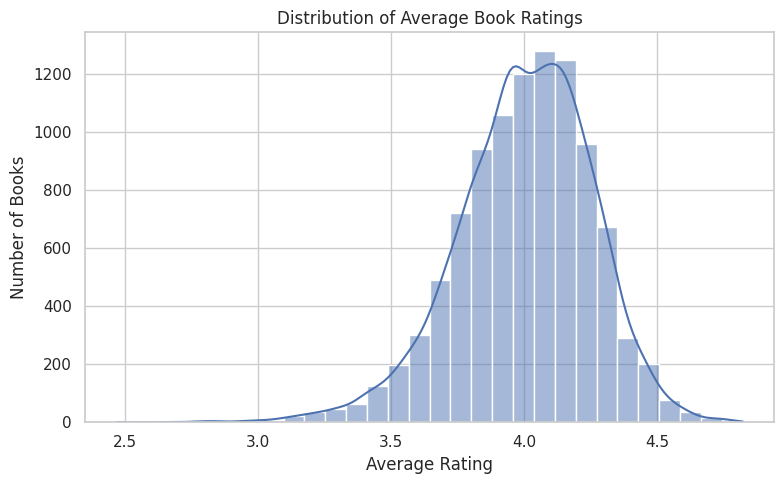

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(df["average_rating"], bins=30, kde=True)
plt.title("Distribution of Average Book Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# Graph 2: Distribution of work ratings on a log scale.

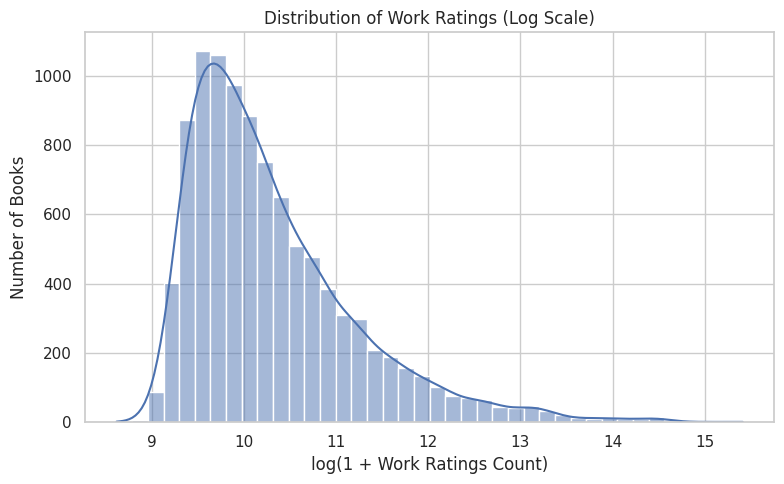

In [8]:
# log1p handles zero values safely.
plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(df["work_ratings_count"]), bins=40, kde=True)
plt.title("Distribution of Work Ratings (Log Scale)")
plt.xlabel("log(1 + Work Ratings Count)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# Graph 3: Publication year distribution

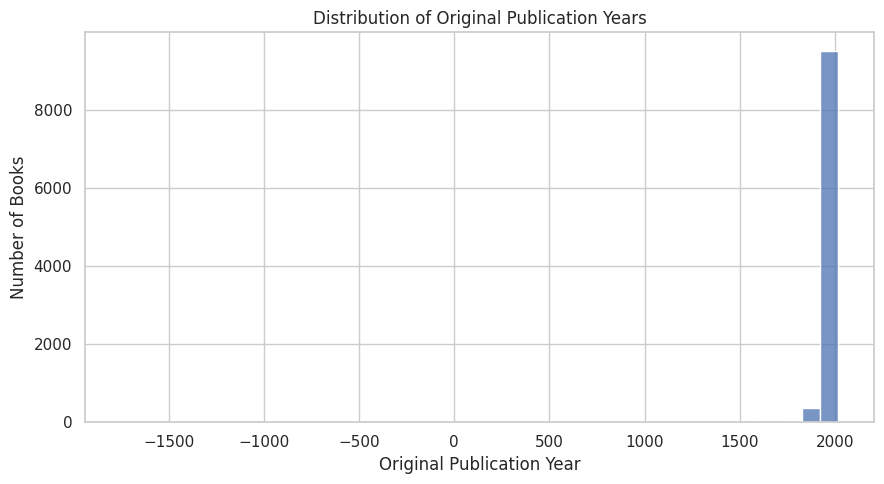

In [9]:
plt.figure(figsize=(9, 5))
sns.histplot(
    df["original_publication_year"].dropna(),
    bins=40
)
plt.title("Distribution of Original Publication Years")
plt.xlabel("Original Publication Year")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# Graph 4: Average rating compared with work ratings

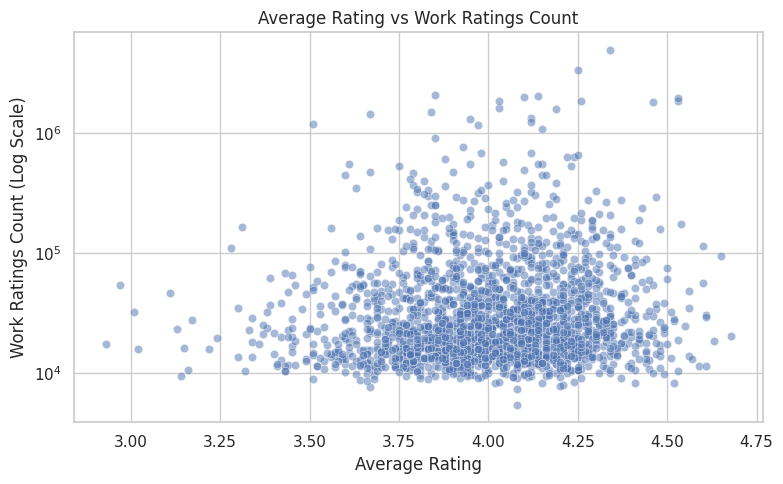

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df.sample(min(2000, len(df)), random_state=42),
    x="average_rating",
    y="work_ratings_count",
    alpha=0.5
)
plt.yscale("log")
plt.title("Average Rating vs Work Ratings Count")
plt.xlabel("Average Rating")
plt.ylabel("Work Ratings Count (Log Scale)")
plt.tight_layout()
plt.show()

# STEP 6: Define the target variable

In [11]:
# The dataset has no official bestseller label.
# Therefore, the top 10% by work_ratings_count is used
# as a proxy for high reader popularity.
threshold = df["work_ratings_count"].quantile(0.90)

df["bestseller_proxy"] = (
    df["work_ratings_count"] >= threshold
).astype(int)

print("\n90th-percentile popularity threshold:", threshold)
print("\nTarget class counts:")
print(df["bestseller_proxy"].value_counts())

print("\nTarget class proportions:")
print(df["bestseller_proxy"].value_counts(normalize=True))


90th-percentile popularity threshold: 104095.00000000003

Target class counts:
bestseller_proxy
0    9000
1    1000
Name: count, dtype: int64

Target class proportions:
bestseller_proxy
0    0.9
1    0.1
Name: proportion, dtype: float64


# Graph 5: Target class balance

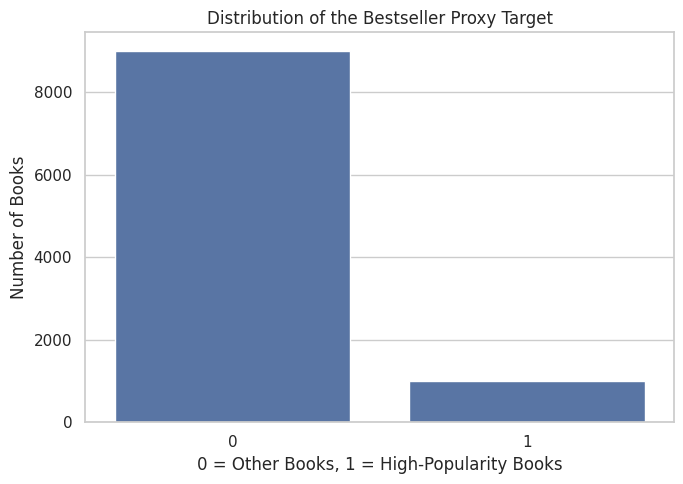

In [12]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="bestseller_proxy")
plt.title("Distribution of the Bestseller Proxy Target")
plt.xlabel("0 = Other Books, 1 = High-Popularity Books")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# STEP 7: Select predictors

In [13]:
# Exclude ratings and reviews because they are used to define
# the target or closely reflect the same popularity outcome.
# Exclude IDs, ISBNs, titles, URLs and author names.
# Keep a limited set of common language categories.
top_languages = set(
    df["language_code"].value_counts().head(6).index
)

df["language_group"] = df["language_code"].where(
    df["language_code"].isin(top_languages), "Other"
)

X = df[
    ["original_publication_year", "books_count", "language_group"]
].copy()

# Convert language categories into numerical dummy variables.
X = pd.get_dummies(
    X, columns=["language_group"], drop_first=True, dtype=float
)

y = df["bestseller_proxy"].to_numpy(dtype=float)

print("\nSelected predictors:")
print(X.columns.tolist())


Selected predictors:
['original_publication_year', 'books_count', 'language_group_Unknown', 'language_group_ara', 'language_group_en-CA', 'language_group_en-GB', 'language_group_en-US', 'language_group_eng']


# STEP 8: Split into training and testing data

In [14]:
# Stratification preserves the minority-class proportion.
X_train, X_test, y_train, y_test = train_test_split(
    X.to_numpy(),
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Standardise using training data only to prevent data leakage.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Add the intercept column (bias term).
X_train = np.column_stack([
    np.ones(X_train.shape[0]), X_train
])
X_test = np.column_stack([
    np.ones(X_test.shape[0]), X_test
])

# STEP 9: Implement Logistic Regression from scratch

In [20]:
def sigmoid(z):
    """Convert linear scores into probabilities."""
    z = np.clip(z, -35, 35)
    return 1 / (1 + np.exp(-z))


def train_logistic_regression(
    X, y, learning_rate=0.05,
    epochs=4000, l2=0.01, positive_weight=1.0
):
    """
    Train Logistic Regression using gradient descent.

    positive_weight=1.0 gives the standard model.
    A larger positive_weight gives more importance to
    incorrectly classifying positive examples.
    """
    weights = np.zeros(X.shape[1])

    # Assign a larger loss weight to positive examples if required.
    sample_weights = np.where(y == 1, positive_weight, 1.0)

    for epoch in range(epochs):
        # Calculate predicted probabilities.
        probabilities = sigmoid(X @ weights)

        # Calculate the gradient of weighted cross-entropy.
        gradient = (
            X.T @ (sample_weights * (probabilities - y))
        ) / len(y)

        # Apply L2 regularisation to coefficients, not intercept.
        gradient[1:] += l2 * weights[1:]

        # Update coefficients in the direction that reduces loss.
        weights -= learning_rate * gradient

    return weights


# STEP 10: Train the initial model

In [16]:
weights = train_logistic_regression(
    X_train, y_train,
    learning_rate=0.05,
    epochs=4000,
    l2=0.01,
    positive_weight=1.0
)

# Predict probabilities and classify at the 0.50 threshold.
probabilities = sigmoid(X_test @ weights)
predictions = (probabilities >= 0.50).astype(int)


def evaluate_model(y_true, y_pred, y_prob, model_name):
    """Display the main model evaluation metrics."""
    print(f"\n{model_name}")
    print("-" * 45)
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(
        precision_score(y_true, y_pred, zero_division=0), 4
    ))
    print("Recall:", round(recall_score(y_true, y_pred), 4))
    print("F1-score:", round(f1_score(y_true, y_pred), 4))
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
    print("\nConfusion matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("\nClassification report:")
    print(classification_report(
        y_true, y_pred, zero_division=0
    ))


evaluate_model(
    y_test, predictions, probabilities,
    "INITIAL LOGISTIC REGRESSION MODEL"
)



INITIAL LOGISTIC REGRESSION MODEL
---------------------------------------------
Accuracy: 0.907
Precision: 0.6944
Recall: 0.125
F1-score: 0.2119
ROC-AUC: 0.8544

Confusion matrix:
[[1789   11]
 [ 175   25]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.91      0.99      0.95      1800
         1.0       0.69      0.12      0.21       200

    accuracy                           0.91      2000
   macro avg       0.80      0.56      0.58      2000
weighted avg       0.89      0.91      0.88      2000



# STEP 11: Visualise the initial confusion matrix

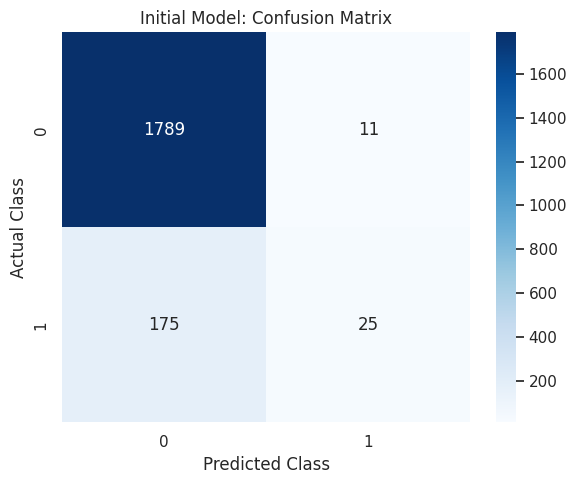

In [17]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test, predictions),
    annot=True, fmt="d", cmap="Blues"
)
plt.title("Initial Model: Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


# STEP 12: Retrain with a higher positive-class weight

In [18]:
# This addresses the problem of missing high-popularity books.
improved_weights = train_logistic_regression(
    X_train, y_train,
    learning_rate=0.03,
    epochs=5000,
    l2=0.01,
    positive_weight=4.0
)

improved_probabilities = sigmoid(X_test @ improved_weights)
improved_predictions = (
    improved_probabilities >= 0.50
).astype(int)

evaluate_model(
    y_test, improved_predictions, improved_probabilities,
    "IMPROVED CLASS-WEIGHTED MODEL"
)


IMPROVED CLASS-WEIGHTED MODEL
---------------------------------------------
Accuracy: 0.904
Precision: 0.5351
Recall: 0.305
F1-score: 0.3885
ROC-AUC: 0.8611

Confusion matrix:
[[1747   53]
 [ 139   61]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.93      0.97      0.95      1800
         1.0       0.54      0.30      0.39       200

    accuracy                           0.90      2000
   macro avg       0.73      0.64      0.67      2000
weighted avg       0.89      0.90      0.89      2000



# STEP 13: Visualise the improved confusion matrix

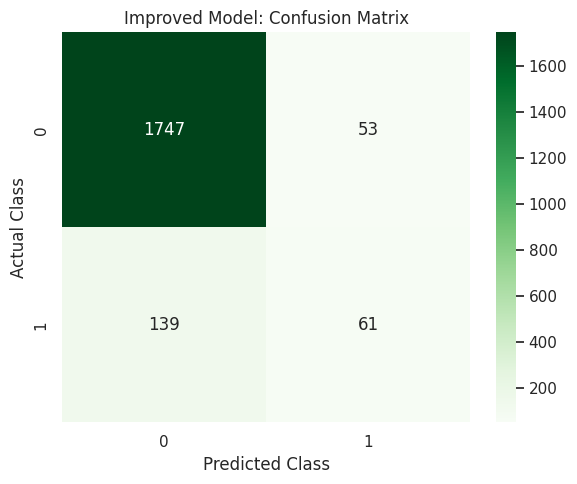

In [21]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test, improved_predictions),
    annot=True, fmt="d", cmap="Greens"
)
plt.title("Improved Model: Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


# STEP 14: Compare both models

In [22]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
    ],
    "Initial Model": [
        accuracy_score(y_test, predictions),
        precision_score(y_test, predictions, zero_division=0),
        recall_score(y_test, predictions),
        f1_score(y_test, predictions),
        roc_auc_score(y_test, probabilities)
    ],
    "Improved Model": [
        accuracy_score(y_test, improved_predictions),
        precision_score(
            y_test, improved_predictions, zero_division=0
        ),
        recall_score(y_test, improved_predictions),
        f1_score(y_test, improved_predictions),
        roc_auc_score(y_test, improved_probabilities)
    ]
})

print("\nMODEL COMPARISON")
print(comparison.round(4).to_string(index=False))



MODEL COMPARISON
   Metric  Initial Model  Improved Model
 Accuracy         0.9070          0.9040
Precision         0.6944          0.5351
   Recall         0.1250          0.3050
 F1-score         0.2119          0.3885
  ROC-AUC         0.8544          0.8611


# STEP 15: Inspect the fitted coefficients

In [23]:
feature_names = ["Intercept"] + X.columns.tolist()

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Initial_Coefficient": weights,
    "Improved_Coefficient": improved_weights
})

print("\nMODEL COEFFICIENTS")
print(coefficient_table.round(4).to_string(index=False))


MODEL COEFFICIENTS
                  Feature  Initial_Coefficient  Improved_Coefficient
                Intercept              -2.3564               -1.0463
original_publication_year               0.2250                0.4439
              books_count               0.7093                1.2744
   language_group_Unknown              -0.3272               -0.3646
       language_group_ara              -0.1190               -0.1732
     language_group_en-CA               0.0856                0.0971
     language_group_en-GB              -0.0196                0.0005
     language_group_en-US               0.1173                0.1720
       language_group_eng               0.1712                0.2340
